# Comprehensive Exploratory Data Analysis (EDA) for 6 Diabetic Retinopathy (DR) Datasets

**Datasets Evaluated:** APTOS 2019, DDR, DeepDRiD, IDRiD, Messidor-2, EyePACS (Kaggle).

**Total Analyzed Cohort:** 55,509 fundus photographs across multi-center international screening programs.

**Primary Objectives:**
1. **Class Imbalance Profiling:** Evaluate the frequency and percentage distribution of Diabetic Retinopathy severity grades (ICDRS Levels 0–4) per dataset and across the unified hybrid cohort.
2. **Image Resolution & Aspect Ratio Analysis:** Quantify spatial resolution diversity, aspect ratio discrepancies, and camera sensor geometry.
3. **Brightness & Color Distribution Analysis:** Extract grayscale mean intensity, channel-wise RGB distributions, and focus sharpness scores to assess domain shifts across camera manufacturers.


In [1]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm import tqdm

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

# Set random seed for strict research reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Matplotlib & Seaborn visualization aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

print(f"[INFO] Environment initialized with SEED={SEED}")


[INFO] Environment initialized with SEED=42


## 1. Dynamic Path Resolution & Configuration Dictionary

Dynamically resolves the path to `data/raw/` regardless of whether the notebook is executed from the repository root or nested pipeline directories.


In [2]:
def get_base_path() -> str:
    """
    Dynamically locates the relative path to `data/raw/` based on current working directory.
    """
    possible_paths = [
        os.path.join("..", "..", "..", "..", "data", "raw"),
        os.path.join("..", "..", "data", "raw"),
        os.path.join("data", "raw")
    ]
    for p in possible_paths:
        if os.path.exists(p):
            return p
    return os.path.join("..", "..", "..", "..", "data", "raw")

BASE_RAW_DIR = get_base_path()
print(f"[INFO] Resolved BASE_RAW_DIR: {BASE_RAW_DIR}")

# Central Configuration Dictionary mapping all 6 DR datasets
DATASET_CONFIG = {
    "APTOS": {
        "name": "APTOS 2019",
        "csv_path": os.path.join("aptos", "aptos_total.csv"),
        "img_dir": os.path.join("aptos", "aptos_total_images"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ".png"
    },
    "DDR": {
        "name": "DDR Dataset",
        "csv_path": os.path.join("ddr", "DR_grading.csv"),
        "img_dir": os.path.join("ddr", "DR_grading", "DR_grading"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ".jpg"
    },
    "DeepDRiD": {
        "name": "DeepDRiD",
        "csv_path": os.path.join("deepdrid", "deepdrid_total.csv"),
        "img_dir": os.path.join("deepdrid", "deepdrid_total_images"),
        "id_col": "image_id",
        "label_col": "patient_DR_Level",
        "id_suffix": ".jpg"
    },
    "IDRiD": {
        "name": "IDRiD",
        "csv_path": os.path.join("idrid", "idrid_total.csv"),
        "img_dir": os.path.join("idrid", "idrid_total_images"),
        "id_col": "image_id",
        "label_col": "diagnosis",
        "id_suffix": ".jpg"
    },
    "Messidor-2": {
        "name": "Messidor-2",
        "csv_path": os.path.join("messidor2preprocess", "messidor_data.csv"),
        "img_dir": os.path.join("messidor2preprocess", "messidor-2", "messidor-2", "preprocess"),
        "id_col": "id_code",
        "label_col": "diagnosis",
        "id_suffix": ""
    },
    "EyePACS": {
        "name": "EyePACS (Kaggle)",
        "csv_path": os.path.join("zipEyepacs", "trainLabels.csv", "trainLabels.csv"),
        "img_dir": os.path.join("zipEyepacs", "train"),
        "id_col": "image",
        "label_col": "level",
        "id_suffix": ".jpeg"
    }
}

# Fallback check for EyePACS CSV path if directory structure varies
eyepacs_alt_csv = os.path.join(BASE_RAW_DIR, "zipEyepacs", "trainLabels.csv")
if not os.path.exists(os.path.join(BASE_RAW_DIR, DATASET_CONFIG["EyePACS"]["csv_path"])) and os.path.isfile(eyepacs_alt_csv):
    DATASET_CONFIG["EyePACS"]["csv_path"] = os.path.join("zipEyepacs", "trainLabels.csv")


[INFO] Resolved BASE_RAW_DIR: ..\..\..\..\data\raw


## 2. Standardized Ingestion, Parsing & Sanity Check Logic

Standardizes raw annotations into uniform schemas (`image_id`, `level`, `patient_id`, `side`), verifying data integrity, detecting duplicate records, dropping missing labels, and filtering out-of-range ordinal values.


In [3]:
def parse_patient_and_side(image_id: str, is_deepdrid: bool = False) -> tuple[str, str]:
    """
    Extracts patient_id and eye lateral side ('left'/'right') from image identifier.
    """
    img_str = str(image_id).lower()
    side = "unknown"
    if "left" in img_str or "_l" in img_str:
        side = "left"
    elif "right" in img_str or "_r" in img_str:
        side = "right"
        
    if is_deepdrid:
        patient_id = img_str.split("_")[0] if "_" in img_str else img_str
    else:
        patient_id = img_str
    return patient_id, side


def load_and_standardize_dataset(key: str, cfg: dict, base_dir: str) -> tuple[pd.DataFrame, dict]:
    """
    Loads raw CSV label file, standardizes column names, checks path validity,
    and extracts lateral eye metadata and integrity statistics.
    """
    full_csv_path = os.path.join(base_dir, cfg["csv_path"])
    full_img_dir = os.path.join(base_dir, cfg["img_dir"])
    
    if not os.path.exists(full_csv_path):
        print(f"[WARNING] CSV path not found: {full_csv_path}")
        return pd.DataFrame(), {}

    raw_df = pd.read_csv(full_csv_path)
    
    # Label column fallback handling
    label_col = cfg["label_col"]
    if label_col not in raw_df.columns:
        possible_labels = [c for c in raw_df.columns if "dr" in c.lower() or "level" in c.lower() or "diagnosis" in c.lower()]
        if possible_labels:
            label_col = possible_labels[0]
            
    df = raw_df[[cfg["id_col"], label_col]].copy()
    df.columns = ["image_id", "level"]
    df["dataset_key"] = key
    df["dataset"] = cfg["name"]
    
    # Ensure correct file extension on image_file
    if cfg["id_suffix"]:
        df["image_file"] = df["image_id"].astype(str).apply(lambda x: x if x.endswith(cfg["id_suffix"]) else x + cfg["id_suffix"])
    else:
        df["image_file"] = df["image_id"].astype(str)
        
    df["full_path"] = df["image_file"].apply(lambda f: os.path.join(full_img_dir, f))
    
    # Sanity checks and auditing
    duplicate_count = int(df["image_id"].duplicated().sum())
    null_count = int(df["level"].isnull().sum())
    
    df["level"] = pd.to_numeric(df["level"], errors="coerce")
    invalid_label_count = int((~df["level"].isin([0, 1, 2, 3, 4])).sum())
    
    df_clean = df.dropna(subset=["level"]).copy()
    df_clean["level"] = df_clean["level"].astype(int)
    df_clean = df_clean[df_clean["level"].isin([0, 1, 2, 3, 4])]
    
    is_deepdrid = ("deepdrid" in key.lower()) or ("deepdrid" in cfg["name"].lower())
    parsed_metadata = df_clean["image_id"].apply(lambda x: parse_patient_and_side(x, is_deepdrid=is_deepdrid))
    df_clean["patient_id"] = [p[0] for p in parsed_metadata]
    df_clean["side"] = [p[1] for p in parsed_metadata]
    
    audit_summary = {
        "total_records": len(df),
        "valid_records": len(df_clean),
        "duplicates": duplicate_count,
        "null_labels": null_count,
        "invalid_labels": invalid_label_count,
        "unique_patients": int(df_clean["patient_id"].nunique()),
        "left_eyes": int((df_clean["side"] == "left").sum()),
        "right_eyes": int((df_clean["side"] == "right").sum())
    }
    
    return df_clean, audit_summary


## 3. Data Loading & Integrity Auditing Execution

Loads all 6 datasets into structured DataFrames and outputs a comprehensive integrity audit table.


In [4]:
dataset_dfs = {}
audit_summaries = {}

print("=" * 70)
print("      MULTI-DATASET INGESTION & SANITY INTEGRITY AUDIT REPORT")
print("=" * 70)

for key, config in DATASET_CONFIG.items():
    df_std, summary = load_and_standardize_dataset(key, config, BASE_RAW_DIR)
    if not df_std.empty:
        dataset_dfs[key] = df_std
        audit_summaries[key] = summary
        print(f"[{config['name']}] Total: {summary['total_records']:,} | Valid: {summary['valid_records']:,} | Patients: {summary['unique_patients']:,}")

audit_df = pd.DataFrame(audit_summaries).T
print("\n=== CONSOLIDATED INTEGRITY AUDIT SUMMARY TABLE ===")
display_cols = ["total_records", "valid_records", "duplicates", "null_labels", "invalid_labels", "unique_patients", "left_eyes", "right_eyes"]
print(audit_df[display_cols].to_string())


      MULTI-DATASET INGESTION & SANITY INTEGRITY AUDIT REPORT
[APTOS 2019] Total: 3,662 | Valid: 3,662 | Patients: 3,662
[DDR Dataset] Total: 12,522 | Valid: 12,522 | Patients: 12,522
[DeepDRiD] Total: 2,000 | Valid: 2,000 | Patients: 500
[IDRiD] Total: 516 | Valid: 516 | Patients: 516
[Messidor-2] Total: 1,744 | Valid: 1,744 | Patients: 1,744
[EyePACS (Kaggle)] Total: 35,126 | Valid: 35,126 | Patients: 35,126

=== CONSOLIDATED INTEGRITY AUDIT SUMMARY TABLE ===
            total_records  valid_records  duplicates  null_labels  invalid_labels  unique_patients  left_eyes  right_eyes
APTOS                3662           3662           0            0               0             3662          0           0
DDR                 12522          12522           0            0               0            12522          0           0
DeepDRiD             2000           2000           0            0               0              500        999        1001
IDRiD                 516            516      

## 4. Aspect 1: Class Distribution & Severity Imbalance Analysis

Diabetic Retinopathy severity grading follows the International Clinical Diabetic Retinopathy Severity (ICDRS) 5-point ordinal scale:
- **Grade 0 (No DR):** Absence of microaneurysms, hemorrhages, or exudates.
- **Grade 1 (Mild DR):** Microaneurysms only.
- **Grade 2 (Moderate DR):** More than microaneurysms, but less than severe NPDR (cotton-wool spots, venous beading).
- **Grade 3 (Severe DR):** >20 intraretinal hemorrhages in each of 4 quadrants, definite venous beading in 2+ quadrants, or prominent IRMA in 1+ quadrant (4-2-1 rule).
- **Grade 4 (Proliferative DR):** Neovascularization, vitreous/preretinal hemorrhage.

### Clinical & Methodological Rationale for Class Imbalance Handling
Real-world diabetic screening populations exhibit extreme positive skewness: Grade 0 constitutes ~65% of samples, whereas critical sight-threatening grades (Grade 3 & Grade 4) represent under 4% each. Standard multi-class Cross-Entropy loss penalizes all misclassifications uniformly and tends to collapse predictions towards majority classes (Grade 0/2). Therefore, **Continuous Quadratic Weighted Kappa (QWK) Loss** and **Cumulative Link Models (CLM / CORAL / CORN)** are required to enforce monotonic penalization proportional to clinical severity distance $|y - \hat{y}|^2$.


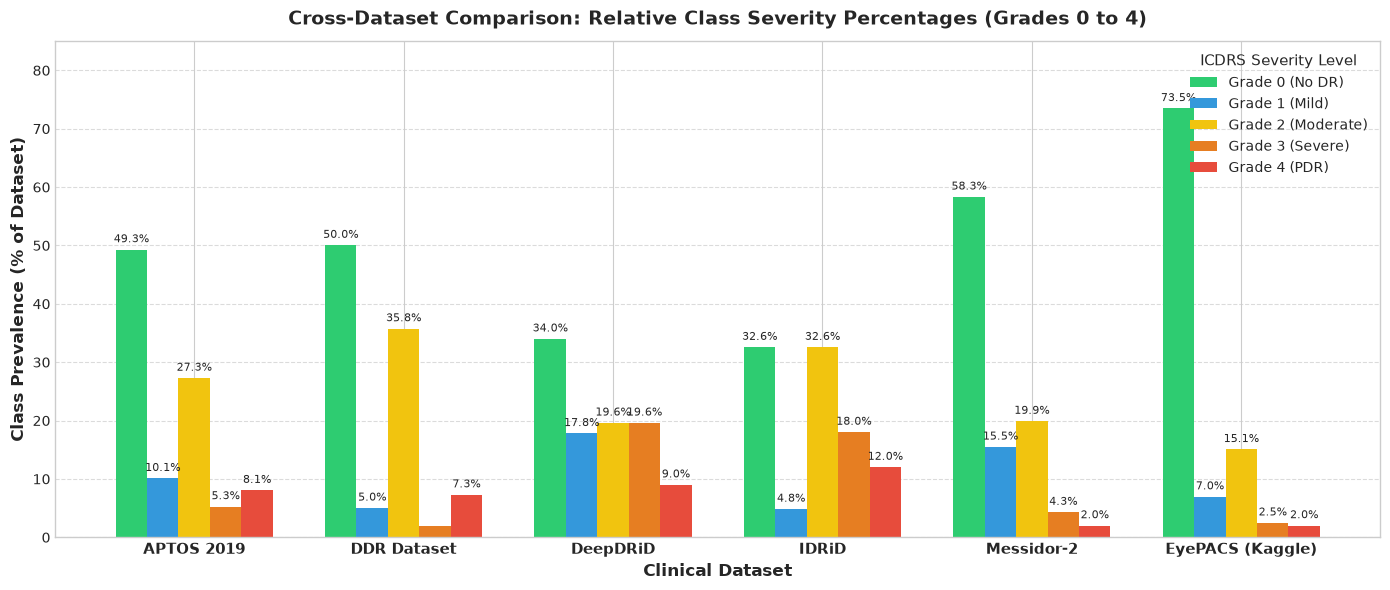

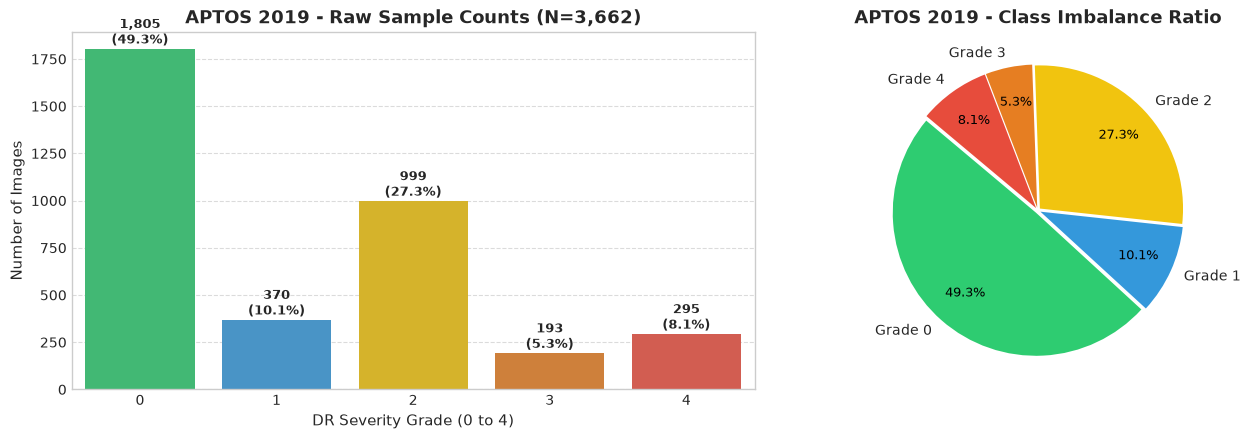

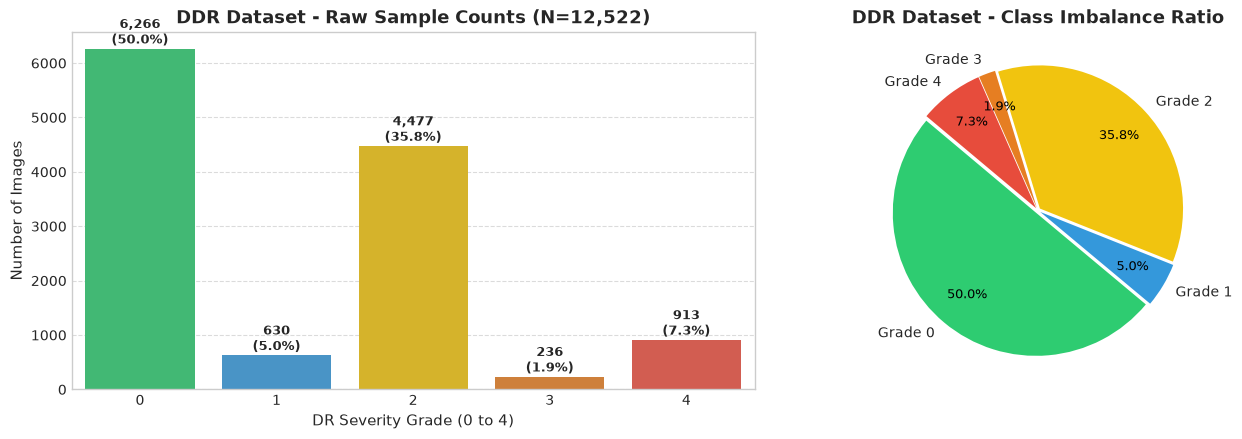

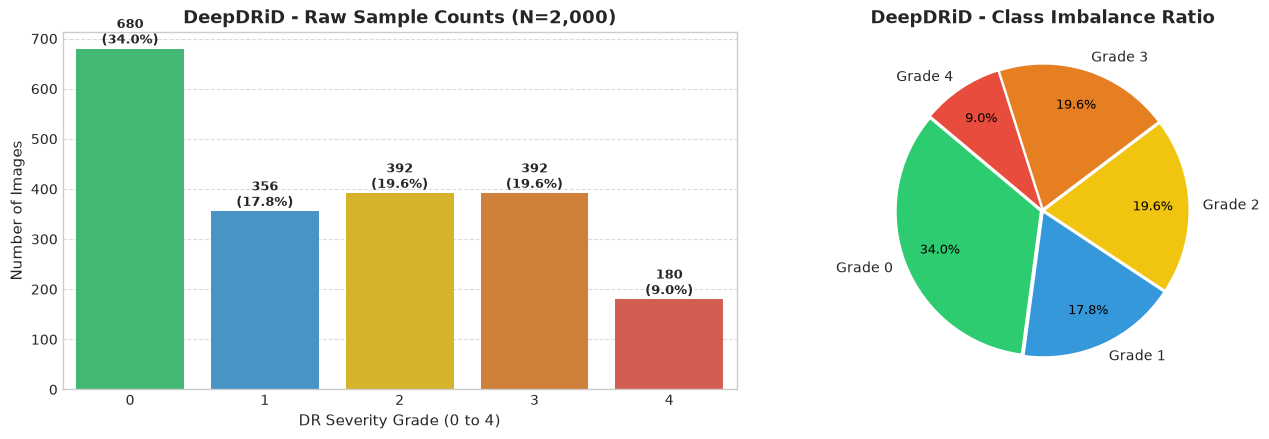

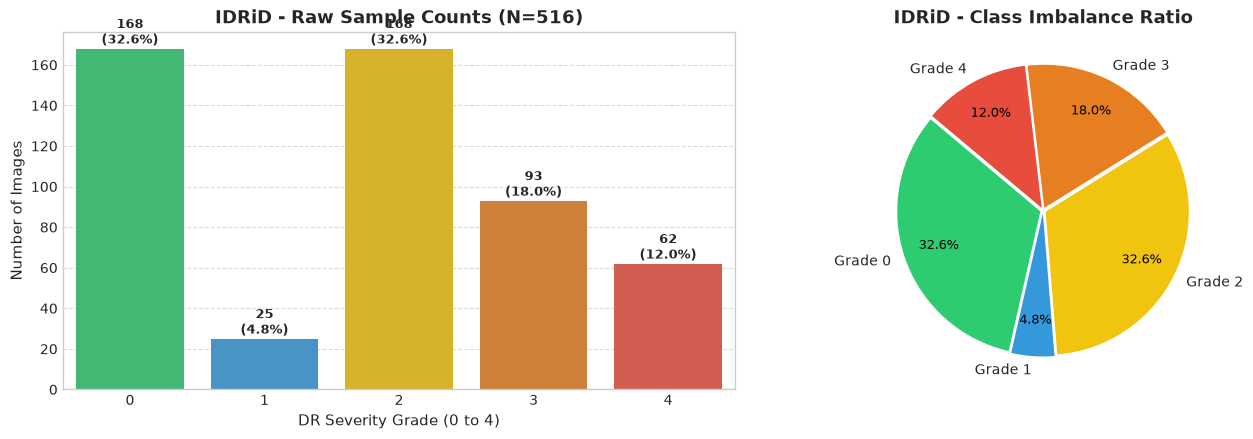

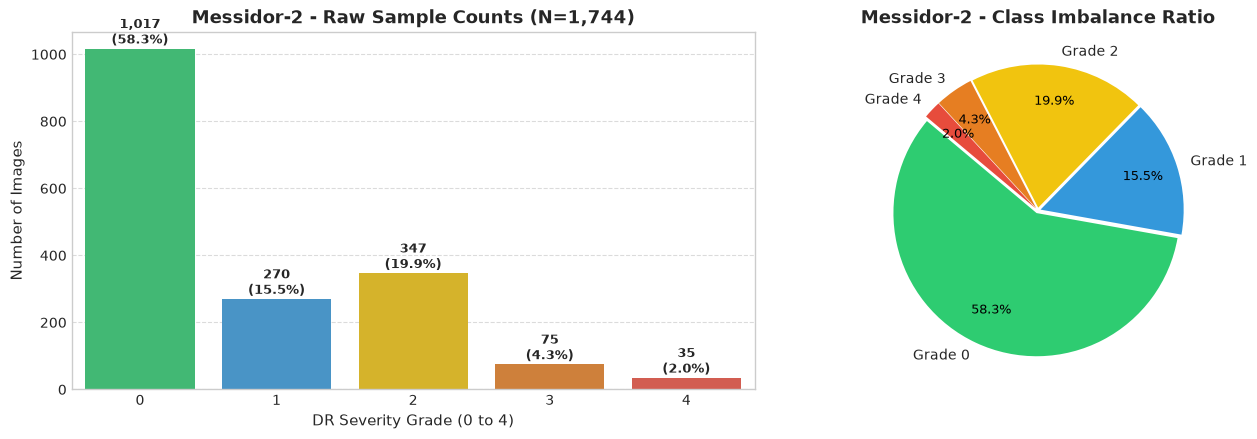

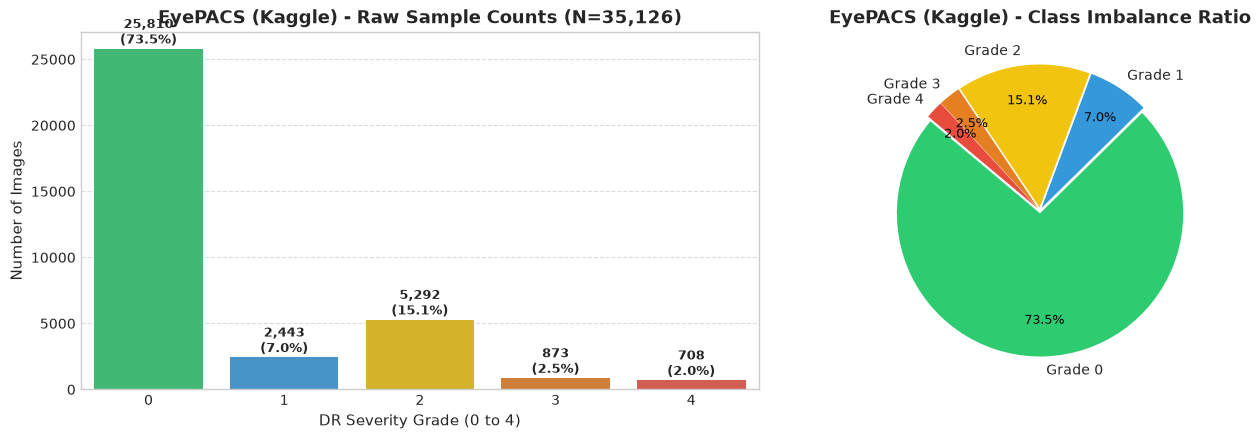

           AUTOMATED CLASS DISTRIBUTION & SEVERITY IMBALANCE SUMMARY TABLE
                        Dataset  Total Images   G0 Count (%) G1 Count (%)   G2 Count (%) G3 Count (%) G4 Count (%) Imbalance Ratio (Max/Min)
                     APTOS 2019          3662  1,805 (49.3%)  370 (10.1%)    999 (27.3%)   193 (5.3%)   295 (8.1%)                     9.35x
                    DDR Dataset         12522  6,266 (50.0%)   630 (5.0%)  4,477 (35.8%)   236 (1.9%)   913 (7.3%)                    26.55x
                       DeepDRiD          2000    680 (34.0%)  356 (17.8%)    392 (19.6%)  392 (19.6%)   180 (9.0%)                     3.78x
                          IDRiD           516    168 (32.6%)    25 (4.8%)    168 (32.6%)   93 (18.0%)   62 (12.0%)                     6.72x
                     Messidor-2          1744  1,017 (58.3%)  270 (15.5%)    347 (19.9%)    75 (4.3%)    35 (2.0%)                    29.06x
               EyePACS (Kaggle)         35126 25,810 (73.5%) 2,443 (7.0%)  5,29

In [5]:
# -------------------------------------------------------------------------
# 4.1 Compute Automated Class Frequency & Imbalance Statistical Table
# -------------------------------------------------------------------------
imbalance_records = []
grade_names = ["Grade 0 (No DR)", "Grade 1 (Mild)", "Grade 2 (Moderate)", "Grade 3 (Severe)", "Grade 4 (PDR)"]

for key, df in dataset_dfs.items():
    total = len(df)
    counts = df["level"].value_counts().reindex(range(5), fill_value=0)
    pcts = (counts / total) * 100
    
    # Imbalance ratio = Max Class Count / Min Class Count
    imbalance_ratio = counts.max() / max(counts.min(), 1)
    
    imbalance_records.append({
        "Dataset": DATASET_CONFIG[key]["name"],
        "Total Images": total,
        "G0 Count (%)": f"{counts[0]:,} ({pcts[0]:.1f}%)",
        "G1 Count (%)": f"{counts[1]:,} ({pcts[1]:.1f}%)",
        "G2 Count (%)": f"{counts[2]:,} ({pcts[2]:.1f}%)",
        "G3 Count (%)": f"{counts[3]:,} ({pcts[3]:.1f}%)",
        "G4 Count (%)": f"{counts[4]:,} ({pcts[4]:.1f}%)",
        "Imbalance Ratio (Max/Min)": f"{imbalance_ratio:.2f}x"
    })

# Compute Aggregated Cohort Metrics
combined_all_dfs = pd.concat(dataset_dfs.values(), ignore_index=True)
total_all = len(combined_all_dfs)
counts_all = combined_all_dfs["level"].value_counts().reindex(range(5), fill_value=0)
pcts_all = (counts_all / total_all) * 100
imbalance_ratio_all = counts_all.max() / max(counts_all.min(), 1)

imbalance_records.append({
    "Dataset": "--- COMBINED 6-DATASET POOL ---",
    "Total Images": total_all,
    "G0 Count (%)": f"{counts_all[0]:,} ({pcts_all[0]:.1f}%)",
    "G1 Count (%)": f"{counts_all[1]:,} ({pcts_all[1]:.1f}%)",
    "G2 Count (%)": f"{counts_all[2]:,} ({pcts_all[2]:.1f}%)",
    "G3 Count (%)": f"{counts_all[3]:,} ({pcts_all[3]:.1f}%)",
    "G4 Count (%)": f"{counts_all[4]:,} ({pcts_all[4]:.1f}%)",
    "Imbalance Ratio (Max/Min)": f"{imbalance_ratio_all:.2f}x"
})

imbalance_summary_df = pd.DataFrame(imbalance_records)
print("=" * 95)
print("           AUTOMATED CLASS DISTRIBUTION & SEVERITY IMBALANCE SUMMARY TABLE")
print("=" * 95)
print(imbalance_summary_df.to_string(index=False))


# -------------------------------------------------------------------------
# 4.2 Comparative Percentage Distribution Across All 6 Datasets
# -------------------------------------------------------------------------
pct_matrix = []
dataset_labels = []
for key, df in dataset_dfs.items():
    total = len(df)
    counts = df["level"].value_counts().reindex(range(5), fill_value=0)
    pct_matrix.append((counts / total * 100).values)
    dataset_labels.append(DATASET_CONFIG[key]["name"])

pct_matrix = np.array(pct_matrix)
colors = ["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(dataset_labels))
width = 0.15

for grade_idx in range(5):
    offset = (grade_idx - 2) * width
    bars = ax.bar(x + offset, pct_matrix[:, grade_idx], width, label=f"Grade {grade_idx} ({grade_names[grade_idx].split('(')[-1].replace(')', '')})", color=colors[grade_idx])
    for bar in bars:
        h = bar.get_height()
        if h > 2.0:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=8, rotation=0)

ax.set_title("Cross-Dataset Comparison: Relative Class Severity Percentages (Grades 0 to 4)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Clinical Dataset", fontsize=12, fontweight="bold")
ax.set_ylabel("Class Prevalence (% of Dataset)", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(dataset_labels, fontsize=11, fontweight="bold")
ax.set_ylim(0, max(pct_matrix.max() + 8, 85))
ax.legend(title="ICDRS Severity Level", fontsize=10, title_fontsize=11, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# 4.3 Individual Dataset Count & Proportion Visualizations
# -------------------------------------------------------------------------
def plot_individual_dataset_distribution(key: str, df: pd.DataFrame, title_name: str):
    counts = df["level"].value_counts().reindex(range(5), fill_value=0)
    total = len(df)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    
    # Bar plot (Count distribution)
    sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=colors)
    axes[0].set_title(f"{title_name} - Raw Sample Counts (N={total:,})", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("DR Severity Grade (0 to 4)", fontsize=11)
    axes[0].set_ylabel("Number of Images", fontsize=11)
    axes[0].grid(axis="y", linestyle="--", alpha=0.7)
    
    for i, count in enumerate(counts.values):
        pct = (count / total) * 100
        axes[0].text(i, count + max(counts.values) * 0.015, f"{count:,}\n({pct:.1f}%)", ha="center", fontsize=9, fontweight="bold")
        
    # Donut / Pie chart (Percentage distribution)
    wedges, texts, autotexts = axes[1].pie(
        counts.values, 
        labels=[f"Grade {i}" for i in range(5)], 
        autopct="%1.1f%%", 
        colors=colors, 
        startangle=140, 
        explode=[0.02]*5,
        pctdistance=0.75
    )
    for autotext in autotexts:
        autotext.set_color("black")
        autotext.set_fontsize(9)
    axes[1].set_title(f"{title_name} - Class Imbalance Ratio", fontsize=13, fontweight="bold")
    
    plt.tight_layout()
    plt.show()

for key, df in dataset_dfs.items():
    plot_individual_dataset_distribution(key, df, DATASET_CONFIG[key]["name"])


## 5. Visualizing Sample Images (1x5 Subplot Grid)

Renders 1 randomly sampled fundus photograph per DR grade (Level 0 through Level 4) for each dataset to visually examine vascular morphology, foveal avascular zone (FAZ), and pathological lesions across acquisition devices.


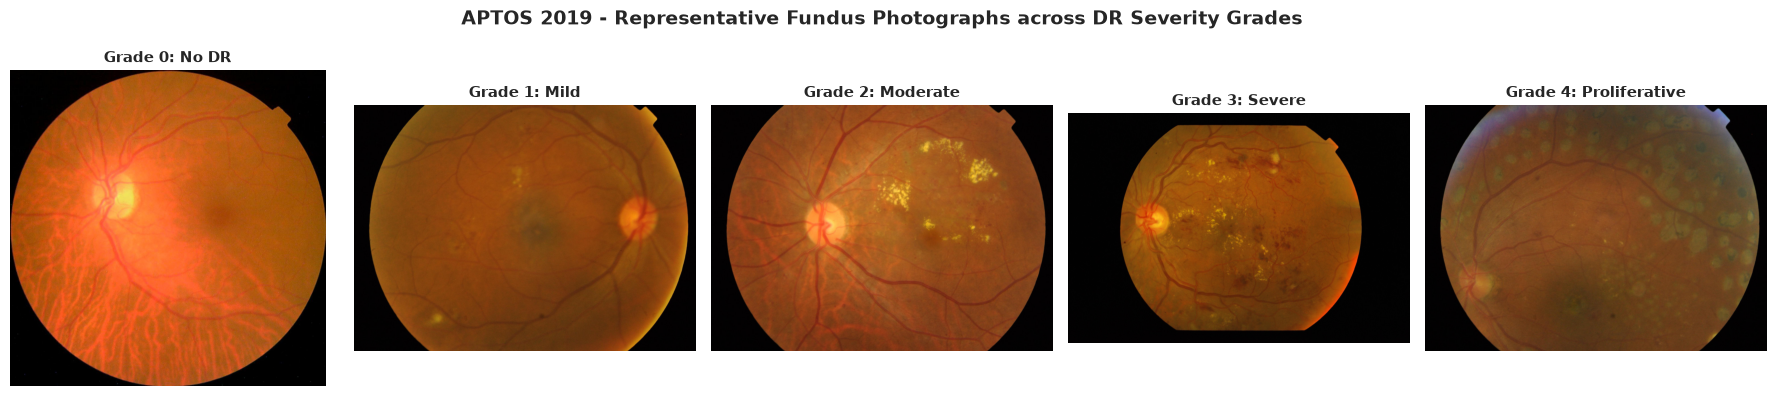

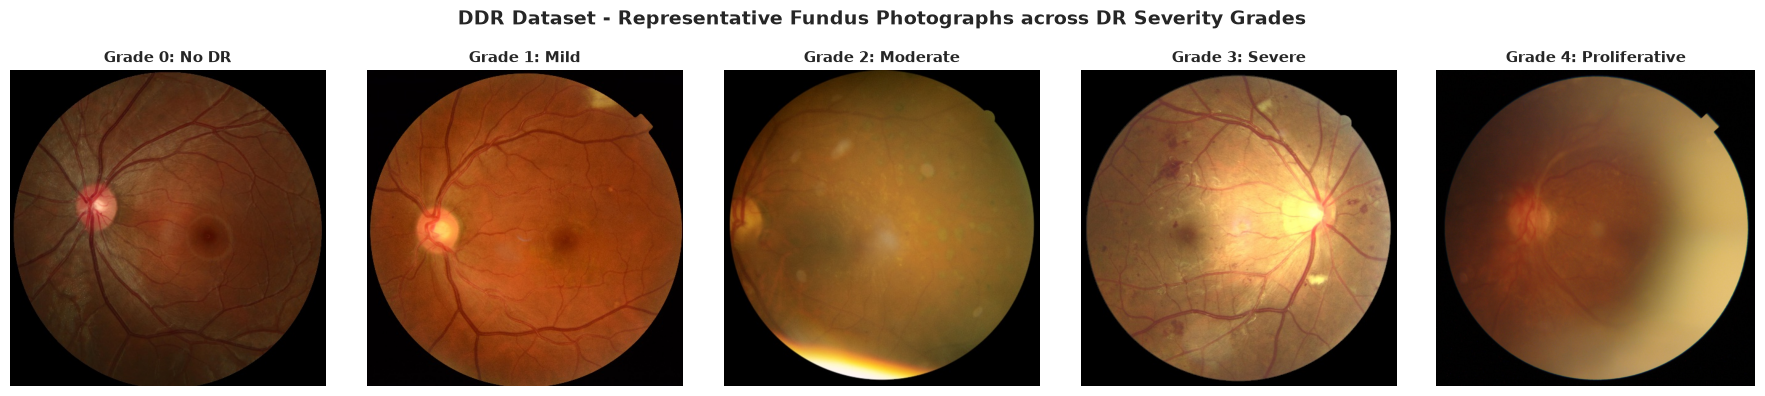

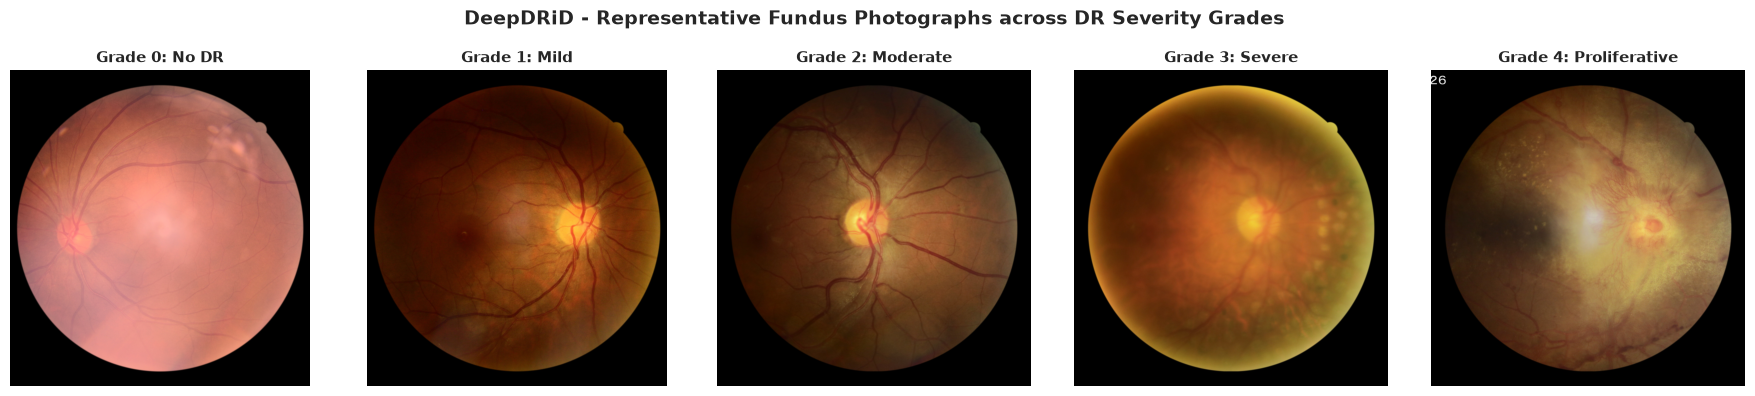

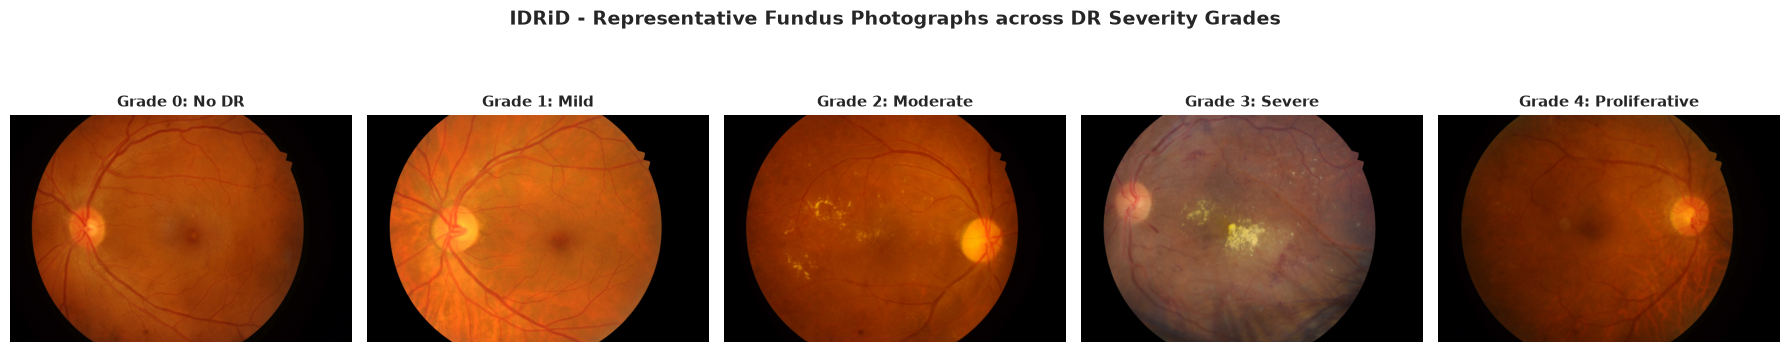

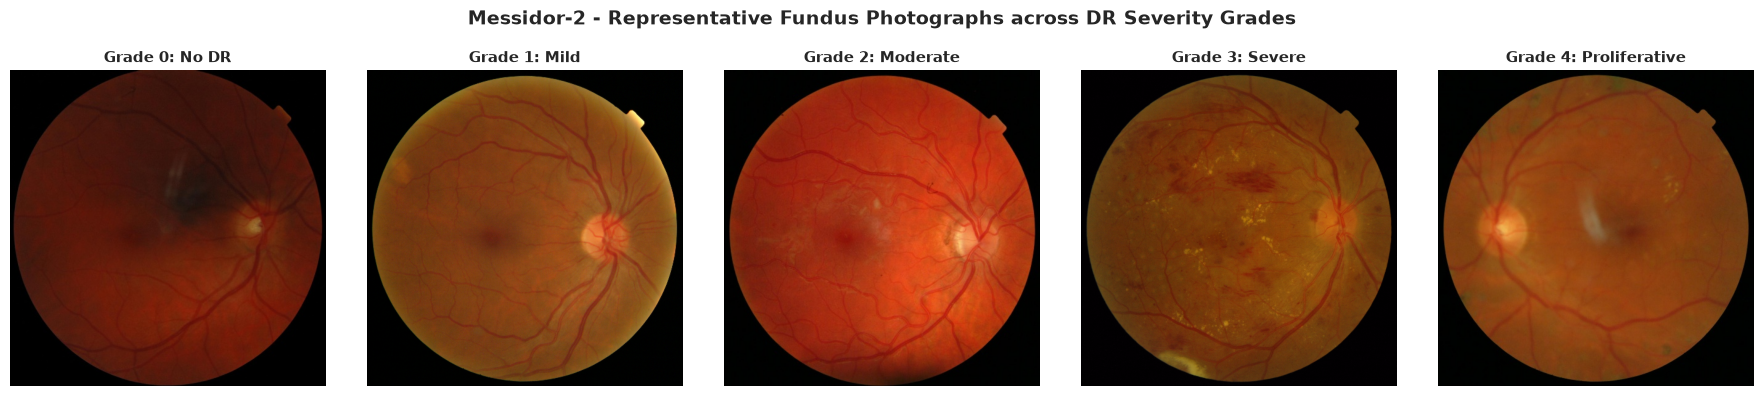

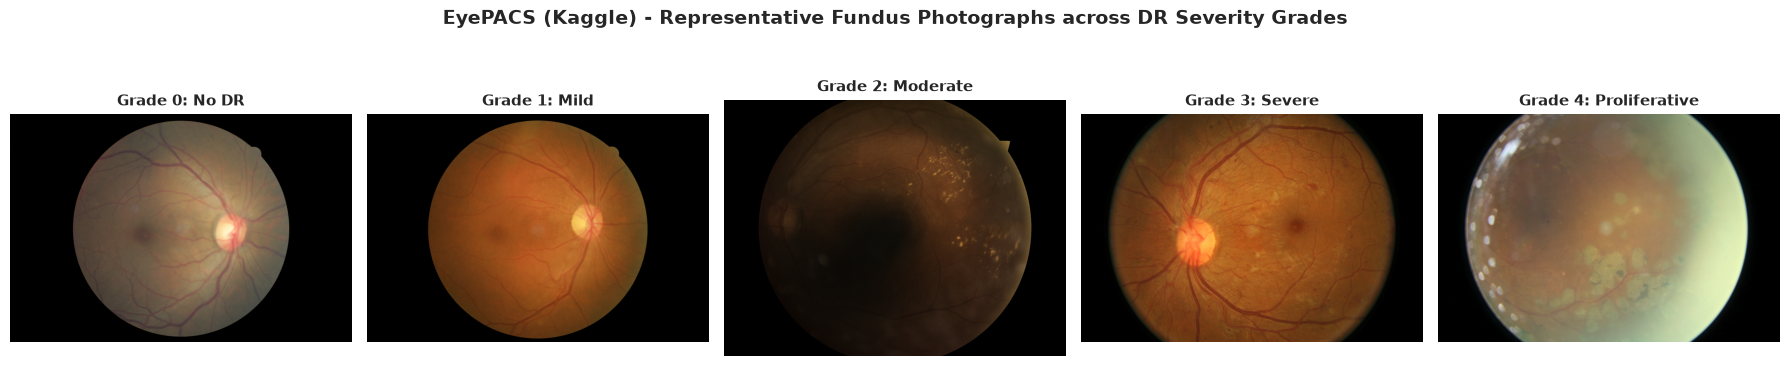

In [6]:
def plot_sample_images_per_level(key: str, df: pd.DataFrame, title_name: str):
    fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
    fig.suptitle(f"{title_name} - Representative Fundus Photographs across DR Severity Grades", fontsize=14, fontweight="bold", y=1.03)
    
    grade_labels = ["0: No DR", "1: Mild", "2: Moderate", "3: Severe", "4: Proliferative"]
    
    for level in range(5):
        ax = axes[level]
        ax.set_title(f"Grade {grade_labels[level]}", fontsize=11, fontweight="bold")
        ax.axis("off")
        
        subset = df[df["level"] == level]
        if subset.empty:
            ax.text(0.5, 0.5, "No Images Available", ha="center", va="center", color="red", fontsize=10)
            continue
            
        sample_row = subset.sample(1, random_state=SEED).iloc[0]
        img_path = sample_row["full_path"]
        
        try:
            if not os.path.exists(img_path):
                ax.text(0.5, 0.5, "File Missing", ha="center", va="center", color="orange", fontsize=10)
                continue
                
            img = Image.open(img_path).convert("RGB")
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, "Read Error", ha="center", va="center", color="red", fontsize=10)
            
    plt.tight_layout()
    plt.show()

for key, df in dataset_dfs.items():
    plot_sample_images_per_level(key, df, DATASET_CONFIG[key]["name"])


## 6. Aspect 2 & 3: Extraction of Resolution, Quality & Color Distribution Metrics

Extracts key computer vision and clinical domain features across a representative sample (100 images per dataset):
1. **Spatial Geometry:** Image Width ($W$), Height ($H$), and Aspect Ratio ($W/H$).
2. **Photometric Brightness & Color:** Grayscale Mean Intensity $\mu_{Gray} \in [0, 255]$, and Channel-wise Mean Intensities $\mu_R, \mu_G, \mu_B$.
3. **Focus Sharpness:** Laplacian Variance focus measure $\sigma^2(\nabla^2 I)$.


In [7]:
def compute_image_metrics_sample(key: str, df: pd.DataFrame, sample_size: int = 100) -> pd.DataFrame:
    """
    Extracts resolution, aspect ratio, grayscale brightness, channel-wise RGB intensities,
    and Laplacian focus sharpness metrics from a random subset of fundus images.
    """
    subset = df.sample(min(sample_size, len(df)), random_state=SEED)
    records = []
    
    for _, row in subset.iterrows():
        img_path = row["full_path"]
        if not os.path.exists(img_path):
            continue
            
        try:
            # Header-level resolution inspection via PIL
            with Image.open(img_path) as img:
                w, h = img.size
                aspect_ratio = float(w) / float(h) if h > 0 else 0.0
                
            # Color and quality metric extraction via OpenCV
            cv_img = cv2.imread(img_path)
            if cv_img is None:
                continue
                
            # Split channels (OpenCV reads in BGR format)
            b_chan, g_chan, r_chan = cv2.split(cv_img)
            gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
            
            brightness = float(np.mean(gray))
            mean_r = float(np.mean(r_chan))
            mean_g = float(np.mean(g_chan))
            mean_b = float(np.mean(b_chan))
            sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
            
            records.append({
                "dataset_key": key,
                "dataset": DATASET_CONFIG[key]["name"],
                "image_id": row["image_id"],
                "level": row["level"],
                "width": w,
                "height": h,
                "aspect_ratio": aspect_ratio,
                "brightness": brightness,
                "mean_red": mean_r,
                "mean_green": mean_g,
                "mean_blue": mean_b,
                "sharpness": sharpness
            })
        except Exception as e:
            continue
            
    return pd.DataFrame(records)

all_metrics_list = []
for key, df in dataset_dfs.items():
    m_df = compute_image_metrics_sample(key, df, sample_size=100)
    all_metrics_list.append(m_df)

combined_metrics_df = pd.concat(all_metrics_list, ignore_index=True)
print(f"[INFO] Extracted quality and color profiles for {len(combined_metrics_df):,} sampled fundus images.")


[INFO] Extracted quality and color profiles for 600 sampled fundus images.


## 7. Statistical Evaluation & Visualizations (Aspects 2 & 3)

### 7.1 Image Resolution & Aspect Ratio Profiling (Aspect 2)
Fundus cameras span various sensor geometries ranging from square cropped sensors ($1:1$ aspect ratio, e.g. Messidor-2 at $512 \times 512$) to rectangular SLR fundus systems ($3:2$ aspect ratio, e.g. IDRiD at $4288 \times 2848$ and EyePACS at $3888 \times 2592$). This spatial diversity mandates circular mask cropping and standardized multi-scale resizing prior to deep neural network ingestion.


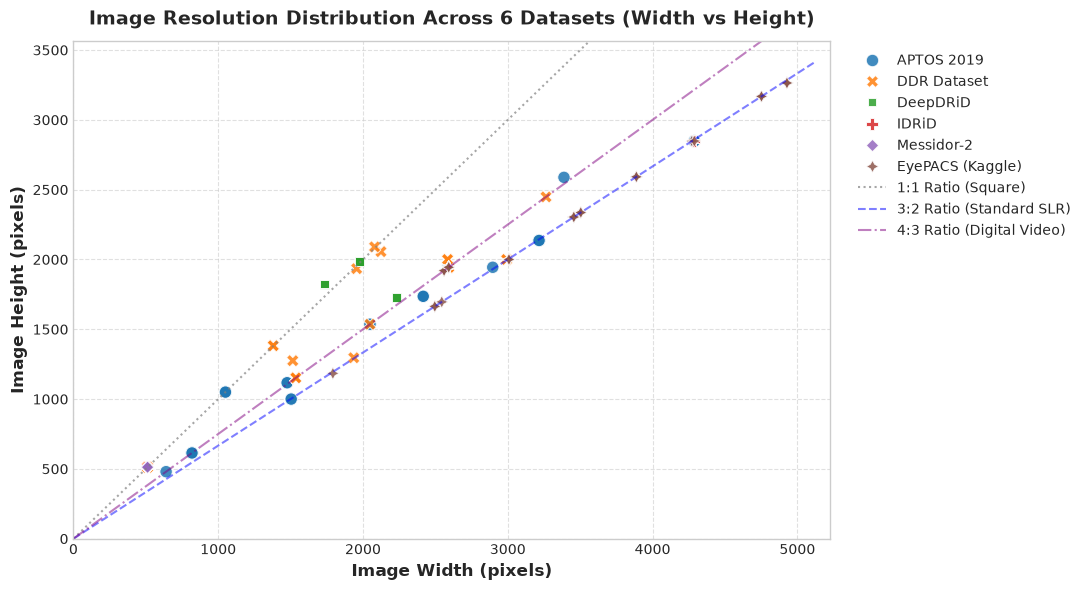

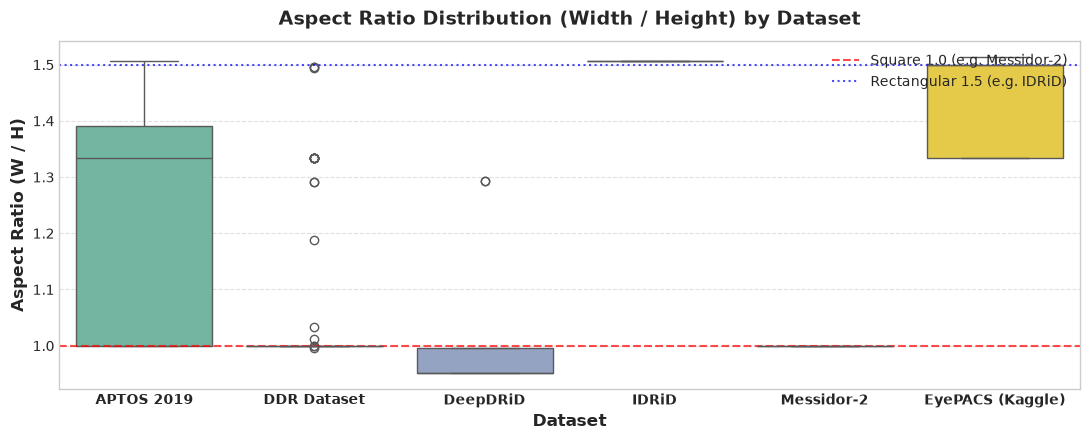

         AUTOMATED IMAGE RESOLUTION & ASPECT RATIO STATISTICAL SUMMARY TABLE
                  Sample_Size  Min_Width  Max_Width  Mean_Width  Std_Width  Min_Height  Max_Height  Mean_Height  Std_Height  Mean_Aspect_Ratio  Std_Aspect_Ratio
dataset                                                                                                                                                         
APTOS 2019                100        640       4288     1885.85     891.27         480        2848      1457.92      511.53               1.25              0.20
DDR Dataset               100        512       3264      816.35     682.29         512        2448       733.67      493.25               1.05              0.13
DeepDRiD                  100       1734       2232     1820.26     125.76        1725        1984      1871.58       76.97               0.97              0.05
EyePACS (Kaggle)          100       1792       4928     3651.20     872.23        1184        3264      2490.48      5

In [8]:
# -------------------------------------------------------------------------
# 7.1 Automated Resolution & Aspect Ratio Statistical Summary Table
# -------------------------------------------------------------------------
res_summary = combined_metrics_df.groupby("dataset").agg(
    Sample_Size=("width", "count"),
    Min_Width=("width", "min"),
    Max_Width=("width", "max"),
    Mean_Width=("width", "mean"),
    Std_Width=("width", "std"),
    Min_Height=("height", "min"),
    Max_Height=("height", "max"),
    Mean_Height=("height", "mean"),
    Std_Height=("height", "std"),
    Mean_Aspect_Ratio=("aspect_ratio", "mean"),
    Std_Aspect_Ratio=("aspect_ratio", "std")
).round(2)

print("=" * 95)
print("         AUTOMATED IMAGE RESOLUTION & ASPECT RATIO STATISTICAL SUMMARY TABLE")
print("=" * 95)
print(res_summary.to_string())

# -------------------------------------------------------------------------
# 7.2 Resolution Scatter Plot (Width vs Height with Aspect Ratio Lines)
# -------------------------------------------------------------------------
plt.figure(figsize=(11, 6))
ax = sns.scatterplot(
    data=combined_metrics_df, 
    x="width", 
    y="height", 
    hue="dataset", 
    style="dataset",
    s=80, 
    alpha=0.85
)

# Reference aspect ratio lines
max_dim = max(combined_metrics_df["width"].max(), combined_metrics_df["height"].max()) + 200
x_ref = np.linspace(0, max_dim, 100)
plt.plot(x_ref, x_ref, color="gray", linestyle=":", label="1:1 Ratio (Square)", alpha=0.7)
plt.plot(x_ref, x_ref * (2/3), color="blue", linestyle="--", label="3:2 Ratio (Standard SLR)", alpha=0.5)
plt.plot(x_ref, x_ref * (3/4), color="purple", linestyle="-.", label="4:3 Ratio (Digital Video)", alpha=0.5)

plt.title("Image Resolution Distribution Across 6 Datasets (Width vs Height)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Image Width (pixels)", fontsize=12, fontweight="bold")
plt.ylabel("Image Height (pixels)", fontsize=12, fontweight="bold")
plt.xlim(0, combined_metrics_df["width"].max() + 300)
plt.ylim(0, combined_metrics_df["height"].max() + 300)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 7.3 Aspect Ratio Distribution Plot
# -------------------------------------------------------------------------
plt.figure(figsize=(11, 4.5))
sns.boxplot(
    data=combined_metrics_df, 
    x="dataset", 
    y="aspect_ratio", 
    palette="Set2"
)
plt.axhline(1.0, color="red", linestyle="--", alpha=0.7, label="Square 1.0 (e.g. Messidor-2)")
plt.axhline(1.5, color="blue", linestyle=":", alpha=0.7, label="Rectangular 1.5 (e.g. IDRiD)")
plt.title("Aspect Ratio Distribution (Width / Height) by Dataset", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Dataset", fontsize=12, fontweight="bold")
plt.ylabel("Aspect Ratio (W / H)", fontsize=12, fontweight="bold")
plt.xticks(fontsize=10, fontweight="bold")
plt.legend(loc="upper right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### 7.2 Brightness & Color Distribution Profiling (Aspect 3)

Differences in retinal illumination and color casts are governed by the optical spectrum of fundus camera flash tubes, sensor quantum efficiency, and cataract opacity. Evaluating channel-wise distributions reveals:
- **Red Channel ($\mu_R$):** Highest mean intensity (~100–140), corresponding to heavy reflectance from choroidal vasculature, often saturated.
- **Green Channel ($\mu_G$):** Moderate intensity (~60–85), containing **optimal clinical contrast** for microaneurysms and hemorrhages due to peak hemoglobin light absorption (~540–577 nm).
- **Blue Channel ($\mu_B$):** Lowest intensity (~15–45), heavily attenuated by ocular media scattering and lens yellowing.


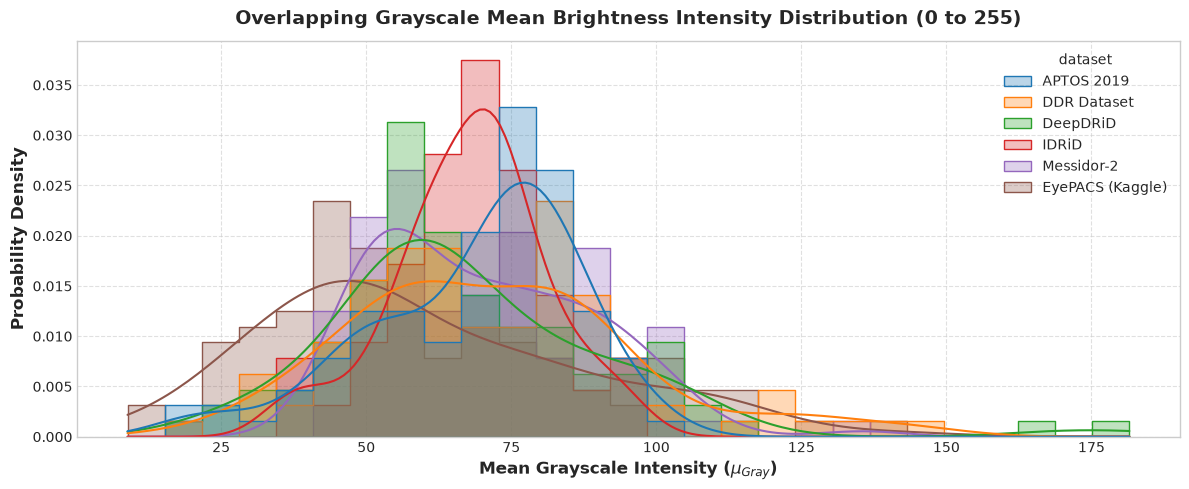

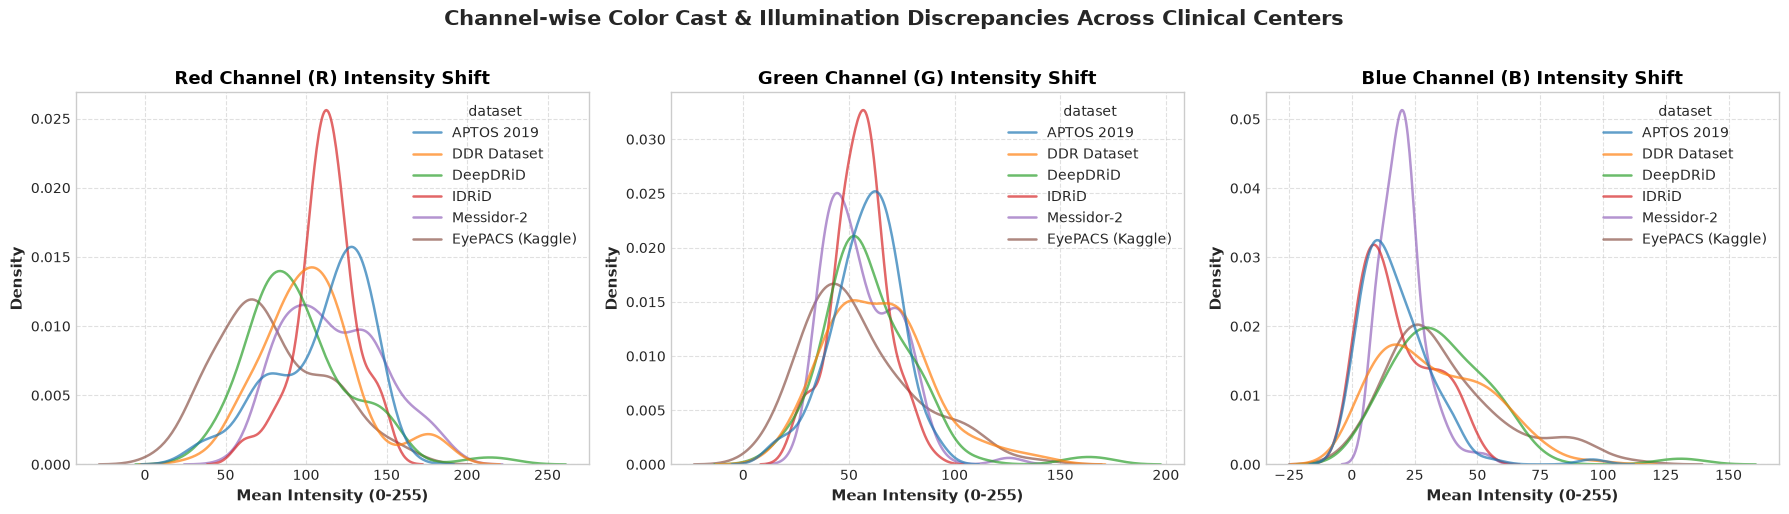

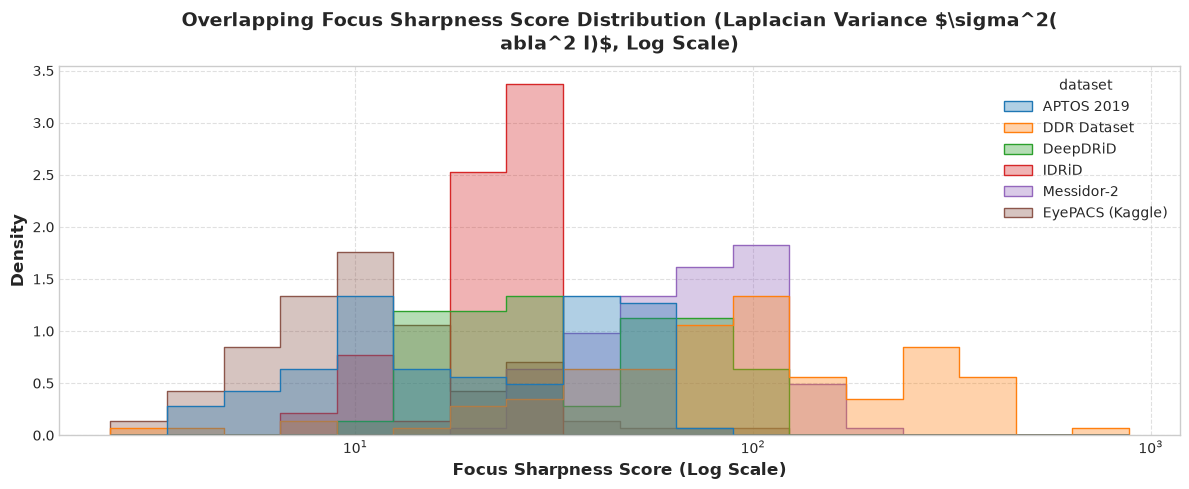

    AUTOMATED BRIGHTNESS, RGB COLOR INTENSITY & SHARPNESS STATISTICAL SUMMARY TABLE
                  Sample_Size  Mean_Brightness  Std_Brightness  Mean_Red  Std_Red  Mean_Green  Std_Green  Mean_Blue  Std_Blue  Mean_Sharpness  Std_Sharpness
dataset                                                                                                                                                     
APTOS 2019                100            68.75           17.82    109.75    29.47       57.78      15.78      17.55     14.03           26.25          17.97
DDR Dataset               100            71.91           24.54    103.03    30.04       63.66      24.22      32.66     21.35          133.43         127.84
DeepDRiD                  100            67.88           25.14     95.66    32.74       59.84      23.28      36.40     21.51           43.00          28.29
EyePACS (Kaggle)          100            59.97           27.47     78.67    33.87       54.75      26.38      37.78     23.77      

In [9]:
# -------------------------------------------------------------------------
# 7.4 Automated Brightness, RGB Color Channels & Sharpness Summary Table
# -------------------------------------------------------------------------
color_summary = combined_metrics_df.groupby("dataset").agg(
    Sample_Size=("brightness", "count"),
    Mean_Brightness=("brightness", "mean"),
    Std_Brightness=("brightness", "std"),
    Mean_Red=("mean_red", "mean"),
    Std_Red=("mean_red", "std"),
    Mean_Green=("mean_green", "mean"),
    Std_Green=("mean_green", "std"),
    Mean_Blue=("mean_blue", "mean"),
    Std_Blue=("mean_blue", "std"),
    Mean_Sharpness=("sharpness", "mean"),
    Std_Sharpness=("sharpness", "std")
).round(2)

print("=" * 95)
print("    AUTOMATED BRIGHTNESS, RGB COLOR INTENSITY & SHARPNESS STATISTICAL SUMMARY TABLE")
print("=" * 95)
print(color_summary.to_string())

# -------------------------------------------------------------------------
# 7.5 Overlapping Grayscale Brightness Distribution (KDE / Histogram)
# -------------------------------------------------------------------------
plt.figure(figsize=(12, 5))
sns.histplot(
    data=combined_metrics_df, 
    x="brightness", 
    hue="dataset", 
    element="step", 
    stat="density", 
    common_norm=False, 
    kde=True,
    alpha=0.3
)
plt.title("Overlapping Grayscale Mean Brightness Intensity Distribution (0 to 255)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Mean Grayscale Intensity ($\mu_{Gray}$)", fontsize=12, fontweight="bold")
plt.ylabel("Probability Density", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 7.6 Channel-wise RGB Color Cast Distribution Comparison
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

channels = [("mean_red", "Red Channel (R)", "#e74c3c"),
            ("mean_green", "Green Channel (G)", "#2ecc71"),
            ("mean_blue", "Blue Channel (B)", "#3498db")]

for idx, (col_name, chan_title, color_code) in enumerate(channels):
    sns.kdeplot(
        data=combined_metrics_df, 
        x=col_name, 
        hue="dataset", 
        ax=axes[idx], 
        common_norm=False, 
        alpha=0.7,
        linewidth=1.8
    )
    axes[idx].set_title(f"{chan_title} Intensity Shift", fontsize=13, fontweight="bold", color="black")
    axes[idx].set_xlabel(f"Mean Intensity (0-255)", fontsize=11, fontweight="bold")
    axes[idx].set_ylabel("Density", fontsize=11, fontweight="bold")
    axes[idx].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Channel-wise Color Cast & Illumination Discrepancies Across Clinical Centers", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 7.7 Image Focus & Sharpness Distribution (Laplacian Variance, Log Scale)
# -------------------------------------------------------------------------
plt.figure(figsize=(12, 5))
sns.histplot(
    data=combined_metrics_df, 
    x="sharpness", 
    hue="dataset", 
    element="step", 
    stat="density", 
    common_norm=False, 
    alpha=0.35,
    log_scale=True
)
plt.title("Overlapping Focus Sharpness Score Distribution (Laplacian Variance $\sigma^2(\nabla^2 I)$, Log Scale)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Focus Sharpness Score (Log Scale)", fontsize=12, fontweight="bold")
plt.ylabel("Density", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### Clinical & Image Processing Takeaways from Quality Profiling

1. **Color Cast Discrepancies & Ben Graham Preprocessing:** Different clinical centers use fundus cameras with distinct color calibrations (e.g., EyePACS and DeepDRiD exhibit mean blue channel ~37–41, whereas APTOS and IDRiD exhibit blue channel ~15–16). Applying **Ben Graham's Color Constancy Filtering** ($I' = 4 \cdot I - 4 \cdot \text{Gaussian}(I) + 128$) standardizes cross-center color balance and suppresses sensor illumination bias.
2. **Green-Channel Contrast Enhancement (CLAHE):** Microaneurysms, intraretinal microvascular abnormalities (IRMA), and hemorrhages are formed by hemoglobin, which maximally absorbs light in the green spectrum (~540–577 nm). Extracting the Green channel and applying Contrast Limited Adaptive Histogram Equalization (**Green-Channel CLAHE**) elevates micro-lesion saliency above choroidal background noise.
3. **Focus & Cataract Opacity Disparities:** EyePACS displays a wide variance in sharpness focus scores with significant low-sharpness tail values (mean focus score 12.56 vs. DDR focus score 139.08), reflecting real-world cataract and media opacity in screening. High-resolution patch-based Multiple Instance Learning (MIL) enables robust diagnostic classification by focusing attention on non-degraded local retinal patches.


## 8. Aggregated Multi-Center Hybrid Cohort Distribution & Final Synthesis

Combines all 6 datasets into an aggregate 55,509-image multi-center training pool and evaluates the global severity distribution.


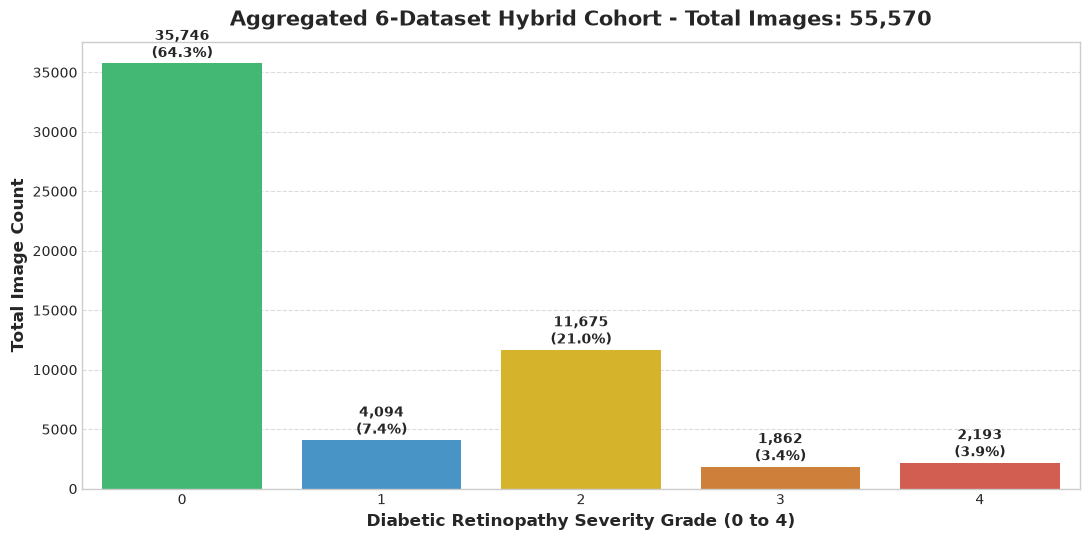

         FINAL AGGREGATED HYBRID COHORT BREAKDOWN
  Grade 0 (No DR): 35,746 images (64.33%)
  Grade 1 (Mild): 4,094 images (7.37%)
  Grade 2 (Moderate): 11,675 images (21.01%)
  Grade 3 (Severe): 1,862 images (3.35%)
  Grade 4 (PDR): 2,193 images (3.95%)
  Total Multi-Center Dataset: 55,570 images


In [10]:
plt.figure(figsize=(11, 5.5))
agg_counts = combined_all_dfs["level"].value_counts().reindex(range(5), fill_value=0)
colors = ["#2ecc71", "#3498db", "#f1c40f", "#e67e22", "#e74c3c"]

ax = sns.barplot(x=agg_counts.index, y=agg_counts.values, palette=colors)
plt.title(f"Aggregated 6-Dataset Hybrid Cohort - Total Images: {len(combined_all_dfs):,}", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Diabetic Retinopathy Severity Grade (0 to 4)", fontsize=12, fontweight="bold")
plt.ylabel("Total Image Count", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.7)

total_images = len(combined_all_dfs)
for i, count in enumerate(agg_counts.values):
    pct = (count / total_images) * 100
    ax.text(i, count + max(agg_counts.values) * 0.015, f"{count:,}\n({pct:.1f}%)", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print("=" * 65)
print("         FINAL AGGREGATED HYBRID COHORT BREAKDOWN")
print("=" * 65)
for grade in range(5):
    cnt = agg_counts[grade]
    print(f"  {grade_names[grade]}: {cnt:,} images ({cnt/total_images*100:.2f}%)")
print(f"  Total Multi-Center Dataset: {total_images:,} images")
print("=" * 65)
